# Bab 5 — Learning multiple weights at a time: generalizing gradient descent

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 5, halaman cetak 79–98 (PDF 100–119, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Menghitung gradien vektor dan outer product, membandingkan pembaruan bebas/beku, serta membaca dot product secara geometris.

## Ringkasan

Aturan gradient descent diperluas ke banyak input, banyak output, dan keduanya sekaligus. Contoh membekukan satu bobot menunjukkan bagaimana bobot lain menyesuaikan diri untuk mengurangi error.

## Konsep, intuisi, dan notasi

Banyak input satu output: $\hat y=x^Tw$, $\nabla_w L=x(\hat y-y)$ dengan $x,w\in\mathbb R^d$. Satu input banyak output: $\hat y=xw$ dan $\nabla_w L=x(\hat y-y)$ tetapi delta sekarang vektor $k$.

Untuk $\hat y=xW$ dengan $x\in\mathbb R^{1\times d}$ dan $\delta\in\mathbb R^{1\times k}$, $\nabla_W L=x^T\delta\in\mathbb R^{d\times k}$. Konvensi baris-per-output buku memakai $\delta^Tx$ berukuran $k\times d$. Ini outer product, bukan dot product skalar.

Pada satu contoh, banyak kombinasi bobot dapat menghasilkan prediksi yang sama. Membekukan bobot bukan berarti menghapus fiturnya: kontribusi tetap ada, hanya gradien update disetel nol. Dot product bergantung pada panjang dan arah vektor; gambar bobot membantu melihat fitur yang mendukung atau menekan output.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b05-multi"></a>

## Reproduksi: multiple inputs dan tiga langkah

**Sumber:** cetak 80–87; PDF 101–108.

Tiga fitur olahraga sama dengan Bab 3. Tahap pembentukan `weight_deltas` yang hilang pada sel awal notebook pendamping dibuat eksplisit sesuai alur buku.

In [2]:
x=np.array([8.5,.65,1.2]); y=1.; initial=np.array([.1,.2,-.1])
def fit_one(freeze=False,alpha=.01):
    w=initial.copy(); rows=[]
    for step in range(3):
        pred=sum(x[i]*w[i] for i in range(3)); delta=pred-y
        gradient=np.array([delta*feature for feature in x])
        if freeze: gradient[0]=0.
        rows.append((step,pred,delta**2,w.copy(),gradient.copy()))
        w-=alpha*gradient
    return w,rows
w,trace=fit_one()
for row in trace: print(row)
assert trace[-1][2]<trace[0][2]

(0, np.float64(0.8600000000000001), np.float64(0.01959999999999997), array([ 0.1,  0.2, -0.1]), array([-1.19 , -0.091, -0.168]))
(1, np.float64(0.9637574999999999), np.float64(0.0013135188062500048), array([ 0.1119 ,  0.20091, -0.09832]), array([-0.308061, -0.023558, -0.043491]))
(2, np.float64(0.9906177228125002), np.float64(8.802712522307997e-05), array([ 0.114981,  0.201146, -0.097885]), array([-0.079749, -0.006098, -0.011259]))


<a id="b05-freeze"></a>

## Reproduksi: freezing one weight

**Sumber:** cetak 88–89; PDF 109–110.

Buku menaikkan alpha menjadi 0,3 setelah bobot fitur jari dibekukan. Ini masuk akal karena fitur dengan skala terbesar tidak lagi ikut diperbarui. Tidak berarti alpha=0,3 aman untuk semua bobot bebas.

In [3]:
frozen,trace_frozen=fit_one(True,.3)
for row in trace_frozen: print(row)
assert frozen[0]==initial[0]
print('Bebas:',w,'Bekukan bobot 0:',frozen)

(0, np.float64(0.8600000000000001), np.float64(0.01959999999999997), array([ 0.1,  0.2, -0.1]), array([ 0.   , -0.091, -0.168]))
(1, np.float64(0.9382250000000001), np.float64(0.003816150624999989), array([ 0.1   ,  0.2273, -0.0496]), array([ 0.      , -0.040154, -0.07413 ]))
(2, np.float64(0.97274178125), np.float64(0.000743010489422852), array([ 0.1     ,  0.239346, -0.027361]), array([ 0.      , -0.017718, -0.03271 ]))
Bebas: [ 0.115778  0.201207 -0.097773] Bekukan bobot 0: [ 0.1       0.244661 -0.017548]


<a id="b05-output"></a>

## Reproduksi: multiple outputs

**Sumber:** cetak 90–91; PDF 111–112.

Setiap output mempunyai delta sendiri terhadap target hurt/win/sad. Error bukan satu tanda yang dipakai untuk seluruh bobot: setiap neuron menerima arah koreksinya masing-masing.

In [4]:
scalar=.65; weights=np.array([.3,.2,.9]); target=np.array([.1,1.,.1])
pred=scalar*weights; delta=pred-target
grad=scalar*delta; updated=weights-.1*grad
print('Prediksi:',pred,'error tiap output:',delta**2,'gradien:',grad,'bobot baru:',updated)

Prediksi: [0.195 0.13  0.585] error tiap output: [0.009025 0.7569   0.235225] gradien: [ 0.06175 -0.5655   0.31525] bobot baru: [0.293825 0.25655  0.868475]


<a id="b05-outer"></a>

## Reproduksi: multiple inputs/outputs dan geometri

**Sumber:** cetak 92–98; PDF 113–119.

Outer product menghubungkan kontribusi setiap input ke kesalahan setiap output. Loop berikut mempertahankan penyimpanan baris-per-output dari buku. Tambahan gradient check memverifikasi seluruh sembilan koefisien.

Outer product:
 [[ 3.8675   0.29575  0.546  ]
 [-0.17    -0.013   -0.024  ]
 [ 7.3525   0.56225  1.038  ]] 
Bobot setelah update:
 [[ 0.061325  0.097043 -0.30546 ]
 [ 0.1017    0.20013   0.00024 ]
 [-0.073525  1.294377  0.08962 ]]


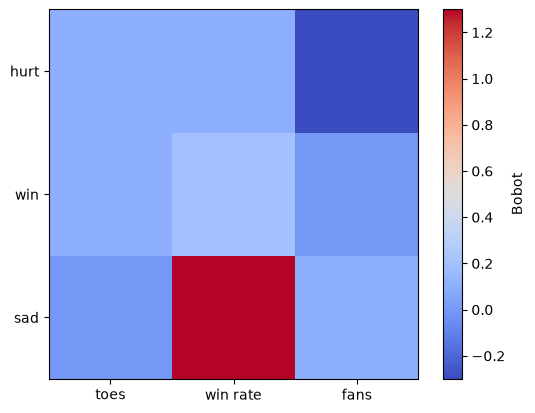

In [5]:
W=np.array([[.1,.1,-.3],[.1,.2,0.],[0.,1.3,.1]])
pred=W@x; delta=pred-target
G=np.zeros_like(W)
for output in range(len(target)):
    for feature in range(len(x)):
        G[output,feature]=delta[output]*x[feature]
np.testing.assert_allclose(G,np.outer(delta,x))
eps=1e-6; numerical=np.zeros_like(W)
for index in np.ndindex(W.shape):
    plus=W.copy(); minus=W.copy(); plus[index]+=eps; minus[index]-=eps
    numerical[index]=(.5*np.sum((plus@x-target)**2)-.5*np.sum((minus@x-target)**2))/(2*eps)
np.testing.assert_allclose(G,numerical,atol=1e-8)
print('Outer product:\n',G,'\nBobot setelah update:\n',W-.01*G)
plt.imshow(W,cmap='coolwarm'); plt.colorbar(label='Bobot')
plt.xticks(range(3),['toes','win rate','fans']); plt.yticks(range(3),['hurt','win','sad']); plt.show()
record(gradient_max_error=float(np.max(np.abs(G-numerical))),frozen_weight=float(frozen[0]))

## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:50:14.884968+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

Bobot yang dibekukan tetap 0.1. Galat maksimum outer-product gradient check 6.535e-11, mendukung penurunan rumus untuk semua koefisien yang diuji.

## Kesimpulan dan pembahasan pertanyaan

Satu aturan lokal menghasilkan gradien skalar, vektor, maupun matriks. Pembekuan mengubah ruang parameter yang dapat dijelajahi; heatmap menggambarkan koefisien, bukan kepentingan kausal fitur.

**Mengapa gradien berbentuk outer product?** Tiap pasangan input-output membutuhkan satu sensitivitas: input_i × delta_j.

**Bisakah bobot beku tetap memengaruhi output?** Ya, forward pass masih memakai nilainya.

**Mengapa besar bobot tidak cukup untuk menentukan pengaruh fitur?** Skala dan korelasi fitur juga menentukan kontribusi.

In [6]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"frozen_weight": 0.1, "gradient_max_error": 6.534572882799239e-11}
